<a href="https://colab.research.google.com/github/fredyotalora-maker/PROYECTO_GRADO/blob/main/proyecto_grado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd


url_archivo = 'https://github.com/fredyotalora-maker/PROYECTO_GRADO/raw/refs/heads/main/FILES/anex-TICH-2025.xlsx'

print("Iniciando Proceso ETL desde GitHub...\n")

# 1. C.3: Acceso a TIC
df_c3_raw = pd.read_excel(url_archivo, sheet_name='C.3', skiprows=11)
df_c3_clean = df_c3_raw.iloc[:, [0, 1, 2, 3]].copy()
df_c3_clean.columns = ['Departamento', 'Area', 'Sexo', 'Total_Personas']
df_c3_clean = df_c3_clean.dropna(how='all')

# 2. C.5: Uso de Internet
df_c5_raw = pd.read_excel(url_archivo, sheet_name='C.5', skiprows=11)
df_c5_clean = df_c5_raw.iloc[:, [0, 1, 2, 3]].copy()
df_c5_clean.columns = ['Departamento', 'Area', 'Sexo', 'Usaron_Internet']
df_c5_clean = df_c5_clean.dropna(how='all')

# 3. C.15: Uso TIC por Nivel Educativo
df_c15_raw = pd.read_excel(url_archivo, sheet_name='C.15', skiprows=11)
df_c15_clean = df_c15_raw.iloc[:, [0, 2, 3, 7, 12]].copy()
df_c15_clean.columns = ['Area', 'Nivel_Educativo', 'Total_Personas', 'Uso_Computador', 'Uso_Internet']
df_c15_clean = df_c15_clean.dropna(subset=['Nivel_Educativo'])
# Filtrado de cohorte
df_secundaria = df_c15_clean[df_c15_clean['Nivel_Educativo'].isin(['Secundaria incompleta', 'Secundaria completa'])]

# 4. C.16: Habilidades informáticas
df_c16_raw = pd.read_excel(url_archivo, sheet_name='C.16', skiprows=10)
df_c16_clean = df_c16_raw.iloc[:, [0, 1, 2, 3]].copy()
df_c16_clean.columns = ['Departamento', 'Area', 'Sexo', 'Usaron_Compu_Internet']
df_c16_clean = df_c16_clean.dropna(how='all')

# IMPRESIÓN DE CONTEOS PARA EL DOCUMENTO WORD
print("--- TABLA DE CONTEOS ANTES Y DESPUÉS ---")
print(f"C.3 (Acceso TIC): Original={len(df_c3_raw)} filas -> Limpio={len(df_c3_clean)} filas.")
print(f"C.5 (Dispositivos): Original={len(df_c5_raw)} filas -> Limpio={len(df_c5_clean)} filas.")
print(f"C.15 (Educación): Original={len(df_c15_raw)} filas -> Limpio={len(df_secundaria)} filas (Solo Secundaria).")
print(f"C.16 (Habilidades): Original={len(df_c16_raw)} filas -> Limpio={len(df_c16_clean)} filas.")

Iniciando Proceso ETL desde GitHub...

--- TABLA DE CONTEOS ANTES Y DESPUÉS ---
C.3 (Acceso TIC): Original=314 filas -> Limpio=312 filas.
C.5 (Dispositivos): Original=314 filas -> Limpio=311 filas.
C.15 (Educación): Original=82 filas -> Limpio=18 filas (Solo Secundaria).
C.16 (Habilidades): Original=316 filas -> Limpio=313 filas.


In [8]:
# ==============================================================================
# BLOQUE 1: CONFIGURACIÓN, SEMILLA FIJA Y CONEXIÓN A GITHUB
# ==============================================================================
import io
import os
import random
import requests
import numpy as np
import pandas as pd
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Semilla fija para garantizar reproducibilidad (requisito técnico ACA)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# URL "Raw" de tu archivo en GitHub (ej. https://raw.githubusercontent.com/TU_USUARIO/PROYECTO_GRADO/main/anex-TICH-2025.xlsx)
# probarlo en local, deja la ruta del archivo subido a Colab.
FUENTE_DATOS = "https://github.com/fredyotalora-maker/PROYECTO_GRADO/raw/refs/heads/main/FILES/anex-TICH-2025.xlsx"
ARCHIVO_LOCAL_FALLBACK = "anex-TICH-2025.xlsx"

def cargar_libro_excel(fuente, fallback):
    if fuente.startswith("http"):
        resp = requests.get(fuente, timeout=30)
        resp.raise_for_status()
        print("✅ Archivo descargado correctamente desde GitHub (Raw).")
        return openpyxl.load_workbook(io.BytesIO(resp.content), data_only=True)
    elif os.path.exists(fallback):
        print(f"✅ Archivo cargado localmente: {fallback}")
        return openpyxl.load_workbook(fallback, data_only=True)
    else:
        raise FileNotFoundError("Configura una URL Raw válida de GitHub o sube el Excel a Colab.")

def to_num(val):
    if val is None:
        return 0.0
    if isinstance(val, (int, float)):
        return float(val)
    try:
        return float(str(val).replace(",", ".").strip())
    except ValueError:
        return 0.0

wb_src = cargar_libro_excel(FUENTE_DATOS, ARCHIVO_LOCAL_FALLBACK)


# ==============================================================================
# BLOQUE 2: EXTRACCIÓN Y LIMPIEZA (ETL) DE HOJAS C.3, C.5, C.15 Y C.16
# ==============================================================================

# --- 2.1 Hoja C.3: Acceso a TIC por Departamento, Área y Sexo ---
ws3 = wb_src["C.3"]
c3_rows = []
for r in range(15, 318):
    c3_rows.append({
        "Departamento": ws3.cell(r, 1).value,
        "Area": ws3.cell(r, 2).value,
        "Sexo": ws3.cell(r, 3).value,
        "Total_Personas_5_Mas": to_num(ws3.cell(r, 4).value),
        "Uso_PC_Escritorio": to_num(ws3.cell(r, 8).value),
        "Uso_PC_Portatil": to_num(ws3.cell(r, 13).value),
        "Uso_Tableta": to_num(ws3.cell(r, 18).value),
        "Uso_Computador_Total": to_num(ws3.cell(r, 23).value),
        "Uso_Internet": to_num(ws3.cell(r, 28).value),
        "Uso_Celular": to_num(ws3.cell(r, 33).value),
        "Tiene_Celular": to_num(ws3.cell(r, 48).value),
        "Tiene_Celular_Convencional": to_num(ws3.cell(r, 53).value),
        "Tiene_Smartphone": to_num(ws3.cell(r, 58).value),
    })
df_c3 = pd.DataFrame(c3_rows)
df_c3["Departamento"] = df_c3["Departamento"].ffill().str.strip()
df_c3["Area"] = df_c3["Area"].ffill().str.strip()
df_c3["Sexo"] = df_c3["Sexo"].str.strip()

c3_total_nacional = df_c3.loc[0, "Total_Personas_5_Mas"]
df_c3_gran = df_c3[
    (df_c3["Departamento"] != "TOTAL NACIONAL") &
    (df_c3["Area"] != "TOTAL") &
    (df_c3["Sexo"] != "TOTAL")
].copy()

# --- 2.2 Hoja C.5: Dispositivos para acceder a Internet (Formato Largo) ---
ws5 = wb_src["C.5"]
dispositivos_map = [
    (8,  "Computador de escritorio", "Productivo / Académico"),
    (13, "Computador portátil",      "Productivo / Académico"),
    (18, "Tableta",                  "Productivo / Académico"),
    (23, "Teléfono celular",         "Consumo / Móvil"),
    (28, "Consolas de juegos",       "Entretenimiento / Otros"),
    (33, "Televisor inteligente",    "Entretenimiento / Otros"),
    (38, "Reproductores digitales",  "Entretenimiento / Otros"),
    (43, "Otro dispositivo",         "Entretenimiento / Otros"),
]
c5_base_rows, c5_long_rows = [], []
for r in range(15, 318):
    c5_base_rows.append({
        "Departamento": ws5.cell(r, 1).value,
        "Area": ws5.cell(r, 2).value,
        "Sexo": ws5.cell(r, 3).value,
        "Base_Internet_C5": to_num(ws5.cell(r, 4).value),
    })
    for col_idx, disp_name, tipo_disp in dispositivos_map:
        c5_long_rows.append({
            "Dispositivo": disp_name,
            "Tipo_Dispositivo": tipo_disp,
            "Usuarios_Miles": to_num(ws5.cell(r, col_idx).value),
        })

df_c5_base = pd.DataFrame(c5_base_rows)
df_c5_base["Departamento"] = df_c5_base["Departamento"].ffill().str.strip()
df_c5_base["Area"] = df_c5_base["Area"].ffill().str.strip()
df_c5_base["Sexo"] = df_c5_base["Sexo"].str.strip()

c5_total_nacional = df_c5_base.loc[0, "Base_Internet_C5"]
df_c5_base_gran = df_c5_base[
    (df_c5_base["Departamento"] != "TOTAL NACIONAL") &
    (df_c5_base["Area"] != "TOTAL") &
    (df_c5_base["Sexo"] != "TOTAL")
].copy()

keys_c5 = df_c5_base[["Departamento", "Area", "Sexo"]].loc[
    df_c5_base.index.repeat(len(dispositivos_map))
].reset_index(drop=True)
df_c5_long = pd.concat([keys_c5, pd.DataFrame(c5_long_rows)], axis=1)
df_c5_long_gran = df_c5_long[
    (df_c5_long["Departamento"] != "TOTAL NACIONAL") &
    (df_c5_long["Area"] != "TOTAL") &
    (df_c5_long["Sexo"] != "TOTAL")
].copy()

# --- 2.3 Hoja C.16: Habilidades Digitales (Formato Largo) ---
ws16 = wb_src["C.16"]
habilidades_map = [
    (8,  "Procesadores de texto (Word/Docs)",       "Básica / Operativa"),
    (13, "Copiar y pegar información",              "Básica / Operativa"),
    (18, "Enviar correos con adjuntos",             "Básica / Operativa"),
    (23, "Conectar o instalar dispositivos",        "Intermedia / Productiva"),
    (28, "Fórmulas matemáticas en hoja de cálculo", "Avanzada / STEM"),
    (33, "Crear presentaciones (PowerPoint/Prezi)", "Intermedia / Productiva"),
    (38, "Transferir archivos entre dispositivos",  "Básica / Operativa"),
    (43, "Instalar y configurar software",          "Intermedia / Productiva"),
    (48, "Lenguaje de programación especializado",  "Avanzada / STEM"),
    (53, "Medidas de seguridad digital",            "Seguridad y Crítica"),
    (58, "Privacidad y protección de datos",        "Seguridad y Crítica"),
    (63, "Verificar veracidad de información",      "Seguridad y Crítica"),
]
c16_base_rows, c16_long_rows = [], []
for r in range(15, 318):
    c16_base_rows.append({
        "Departamento": ws16.cell(r, 1).value,
        "Area": ws16.cell(r, 2).value,
        "Sexo": ws16.cell(r, 3).value,
        "Base_PC_Internet_C16": to_num(ws16.cell(r, 4).value),
    })
    for col_idx, hab_name, cat_hab in habilidades_map:
        c16_long_rows.append({
            "Habilidad": hab_name,
            "Categoria_Habilidad": cat_hab,
            "Usuarios_Miles": to_num(ws16.cell(r, col_idx).value),
        })

df_c16_base = pd.DataFrame(c16_base_rows)
df_c16_base["Departamento"] = df_c16_base["Departamento"].ffill().str.strip()
df_c16_base["Area"] = df_c16_base["Area"].ffill().str.strip()
df_c16_base["Sexo"] = df_c16_base["Sexo"].str.strip()

c16_total_nacional = df_c16_base.loc[0, "Base_PC_Internet_C16"]
df_c16_base_gran = df_c16_base[
    (df_c16_base["Departamento"] != "TOTAL NACIONAL") &
    (df_c16_base["Area"] != "TOTAL") &
    (df_c16_base["Sexo"] != "TOTAL")
].copy()

keys_c16 = df_c16_base[["Departamento", "Area", "Sexo"]].loc[
    df_c16_base.index.repeat(len(habilidades_map))
].reset_index(drop=True)
df_c16_long = pd.concat([keys_c16, pd.DataFrame(c16_long_rows)], axis=1)
df_c16_long_gran = df_c16_long[
    (df_c16_long["Departamento"] != "TOTAL NACIONAL") &
    (df_c16_long["Area"] != "TOTAL") &
    (df_c16_long["Sexo"] != "TOTAL")
].copy()

# Consolidar bases de C.5 y C.16 en Fact_C3 (mismo grano: Depto + Área + Sexo)
df_fact_c3 = (
    df_c3_gran
    .merge(df_c5_base_gran, on=["Departamento", "Area", "Sexo"], how="left")
    .merge(df_c16_base_gran, on=["Departamento", "Area", "Sexo"], how="left")
)

# --- 2.4 Hoja C.15: Uso TIC por Nivel Educativo ---
ws15 = wb_src["C.15"]
c15_rows = []
for r in range(14, 86):
    c15_rows.append({
        "Area": ws15.cell(r, 1).value,
        "Sexo": ws15.cell(r, 2).value,
        "Nivel_Educativo": ws15.cell(r, 3).value,
        "Total_Personas_5_Mas": to_num(ws15.cell(r, 4).value),
        "Uso_Computador": to_num(ws15.cell(r, 8).value),
        "Uso_Internet": to_num(ws15.cell(r, 13).value),
        "Uso_Celular": to_num(ws15.cell(r, 18).value),
        "Escucho_Radio": to_num(ws15.cell(r, 23).value),
        "Tiene_Celular": to_num(ws15.cell(r, 28).value),
    })
df_c15 = pd.DataFrame(c15_rows)
df_c15["Area"] = df_c15["Area"].ffill().str.strip()
df_c15["Sexo"] = df_c15["Sexo"].ffill().str.strip()
df_c15["Nivel_Educativo"] = df_c15["Nivel_Educativo"].str.strip()

c15_total_nacional = df_c15.loc[0, "Total_Personas_5_Mas"]
df_fact_c15 = df_c15[
    (df_c15["Area"] != "TOTAL") &
    (~df_c15["Sexo"].str.contains("TOTAL", na=False)) &
    (df_c15["Nivel_Educativo"] != "Total")
].copy()


# ==============================================================================
# BLOQUE 3: CONSTRUCCIÓN DEL MODELO ESTRELLA (DIMENSIONES Y HECHOS)
# ==============================================================================
deptos_sorted = sorted(df_fact_c3["Departamento"].unique())
def formato_mapa(d):
    especiales = {
        "BOGOTÁ, D.C.": "Bogotá, Colombia",
        "SAN ANDRÉS": "San Andrés y Providencia, Colombia",
        "VALLE DEL CAUCA": "Valle del Cauca, Colombia",
        "NORTE DE SANTANDER": "Norte de Santander, Colombia",
        "LA GUAJIRA": "La Guajira, Colombia",
    }
    return especiales.get(d, f"{d.title()}, Colombia")

dim_depto = pd.DataFrame({
    "Departamento_ID": range(1, len(deptos_sorted) + 1),
    "Departamento": deptos_sorted,
    "Departamento_Mapa": [formato_mapa(d) for d in deptos_sorted],
})

dim_area = pd.DataFrame({
    "Area_ID": [1, 2],
    "Area": ["CABECERA", "CENTROS POBLADOS Y RURAL DISPERSO"],
    "Area_Corta": ["Urbano (Cabecera)", "Rural / Centros Poblados"],
})

dim_sexo = pd.DataFrame({
    "Sexo_ID": [1, 2],
    "Sexo": ["HOMBRE", "MUJER"],
    "Sexo_Etiqueta": ["Hombre", "Mujer"],
})

niveles_orden = [
    ("Ninguno",               "Otros Niveles",                   1),
    ("Primaria incompleta",   "Otros Niveles",                   2),
    ("Primaria completa",     "Otros Niveles",                   3),
    ("Secundaria incompleta", "Población Objetivo (Secundaria)", 4),
    ("Secundaria completa",   "Población Objetivo (Secundaria)", 5),
    ("Superior incompleta",   "Educación Superior",              6),
    ("Superior completa",     "Educación Superior",              7),
]
dim_nivel = pd.DataFrame(niveles_orden, columns=["Nivel_Educativo", "Grupo_Proyecto", "Orden"])
dim_nivel.insert(0, "Nivel_ID", range(1, len(niveles_orden) + 1))

# Mapeo de llaves foráneas (IDs)
map_depto = dict(zip(dim_depto["Departamento"], dim_depto["Departamento_ID"]))
map_area  = dict(zip(dim_area["Area"], dim_area["Area_ID"]))
map_sexo  = dict(zip(dim_sexo["Sexo"], dim_sexo["Sexo_ID"]))
map_nivel = dict(zip(dim_nivel["Nivel_Educativo"], dim_nivel["Nivel_ID"]))

for df in [df_fact_c3, df_c5_long_gran, df_c16_long_gran]:
    df["Departamento_ID"] = df["Departamento"].map(map_depto)
    df["Area_ID"] = df["Area"].map(map_area)
    df["Sexo_ID"] = df["Sexo"].map(map_sexo)

df_fact_c15["Area_ID"]  = df_fact_c15["Area"].map(map_area)
df_fact_c15["Sexo_ID"]  = df_fact_c15["Sexo"].map(map_sexo)
df_fact_c15["Nivel_ID"] = df_fact_c15["Nivel_Educativo"].map(map_nivel)

fact_c3_final = df_fact_c3[[
    "Departamento_ID", "Area_ID", "Sexo_ID", "Total_Personas_5_Mas",
    "Uso_Computador_Total", "Uso_PC_Escritorio", "Uso_PC_Portatil", "Uso_Tableta",
    "Uso_Internet", "Uso_Celular", "Tiene_Celular", "Tiene_Smartphone",
    "Tiene_Celular_Convencional", "Base_Internet_C5", "Base_PC_Internet_C16"
]].copy()

fact_c5_final  = df_c5_long_gran[["Departamento_ID", "Area_ID", "Sexo_ID", "Dispositivo", "Tipo_Dispositivo", "Usuarios_Miles"]].copy()
fact_c15_final = df_fact_c15[["Area_ID", "Sexo_ID", "Nivel_ID", "Total_Personas_5_Mas", "Uso_Computador", "Uso_Internet", "Uso_Celular", "Tiene_Celular", "Escucho_Radio"]].copy()
fact_c16_final = df_c16_long_gran[["Departamento_ID", "Area_ID", "Sexo_ID", "Habilidad", "Categoria_Habilidad", "Usuarios_Miles"]].copy()


# ==============================================================================
# BLOQUE 4: AUDITORÍA DE CALIDAD Y EXPORTACIÓN A EXCEL PARA POWER BI
# ==============================================================================
df_qa = pd.DataFrame([
    ("C.3 - Población 5+ años (miles)",              c3_total_nacional,  fact_c3_final["Total_Personas_5_Mas"].sum(),  len(fact_c3_final)),
    ("C.5 - Usuarios Internet (miles)",              c5_total_nacional,  fact_c3_final["Base_Internet_C5"].sum(),      len(fact_c5_final)),
    ("C.15 - Población por Nivel Educativo (miles)", c15_total_nacional, fact_c15_final["Total_Personas_5_Mas"].sum(), len(fact_c15_final)),
    ("C.16 - Usuarios PC o Internet (miles)",        c16_total_nacional, fact_c3_final["Base_PC_Internet_C16"].sum(),  len(fact_c16_final)),
], columns=["Tabla / Indicador", "Total Nacional DANE", "Suma Modelo Estrella", "Filas en Modelo"])
df_qa["Diferencia"] = (df_qa["Total Nacional DANE"] - df_qa["Suma Modelo Estrella"]).round(6)

print("\n=== AUDITORÍA DE INTEGRIDAD (0.00 = CUADRE EXACTO) ===")
print(df_qa.to_string(index=False))

# Exportación formateada lista para Power BI
wb_out = openpyxl.Workbook()
wb_out.remove(wb_out.active)

header_fill = PatternFill(start_color="1B365D", end_color="1B365D", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")

def escribir_hoja(wb, nombre, df):
    ws = wb.create_sheet(title=nombre)
    for c_idx, col_name in enumerate(df.columns, 1):
        cell = ws.cell(row=1, column=c_idx, value=col_name)
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(horizontal="center")
    for r_idx, row in enumerate(df.itertuples(index=False), 2):
        for c_idx, val in enumerate(row, 1):
            ws.cell(row=r_idx, column=c_idx, value=val)
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = f"A1:{get_column_letter(len(df.columns))}{len(df)+1}"

for nombre, tabla in [
    ("Resumen_Validacion",      df_qa),
    ("Dim_Departamento",        dim_depto),
    ("Dim_Area",                dim_area),
    ("Dim_Sexo",                dim_sexo),
    ("Dim_Nivel_Educativo",     dim_nivel),
    ("Fact_C3_Acceso_TIC",      fact_c3_final),
    ("Fact_C5_Dispositivos",    fact_c5_final),
    ("Fact_C15_Nivel_Educativo", fact_c15_final),
    ("Fact_C16_Habilidades",    fact_c16_final),
]:
    escribir_hoja(wb_out, nombre, tabla)

archivo_salida = "Modelo_Estrella_PowerBI_TICH2025.xlsx"
wb_out.save(archivo_salida)
print(f"\n🚀 ¡Exportación exitosa! Archivo generado: {archivo_salida}")

✅ Archivo descargado correctamente desde GitHub (Raw).

=== AUDITORÍA DE INTEGRIDAD (0.00 = CUADRE EXACTO) ===
                           Tabla / Indicador  Total Nacional DANE  Suma Modelo Estrella  Filas en Modelo  Diferencia
             C.3 - Población 5+ años (miles)         50076.096237          50076.096237              130        -0.0
             C.5 - Usuarios Internet (miles)         41193.581832          41193.581832             1040         0.0
C.15 - Población por Nivel Educativo (miles)         50076.096241          50076.096241               28         0.0
       C.16 - Usuarios PC o Internet (miles)         41329.808801          41329.808801             1560         0.0

🚀 ¡Exportación exitosa! Archivo generado: Modelo_Estrella_PowerBI_TICH2025.xlsx


=== AUDITORÍA DE VALORES FALTANTES (POST-ETL) ===
  Fact_C3: 130 filas x 15 columnas | Nulos: 0
  Fact_C5: 1040 filas x 6 columnas | Nulos: 0
  Fact_C15: 28 filas x 9 columnas | Nulos: 0
  Fact_C16: 1560 filas x 6 columnas | Nulos: 0

=== TABLA 4A: ESTRATIFICACIÓN POR ÁREA ===
                               Pob  Pct_Internet  Pct_PC  Pct_Celular  \
Area_Corta                                                              
Rural / Centros Poblados  11435.28         70.64   17.94        86.67   
Urbano (Cabecera)         38640.82         85.70   41.45        93.46   

                          Brecha_pp  Pct_Excel  Pct_Prog  
Area_Corta                                                
Rural / Centros Poblados      52.70      15.30      2.94  
Urbano (Cabecera)             44.25      35.47     11.87  

=== TABLA 4B: ESTRATIFICACIÓN POR SEXO ===
                    Pob  Pct_Internet  Pct_PC  Brecha_pp  Pct_Excel  Pct_Prog
Sexo_Etiqueta                                                          

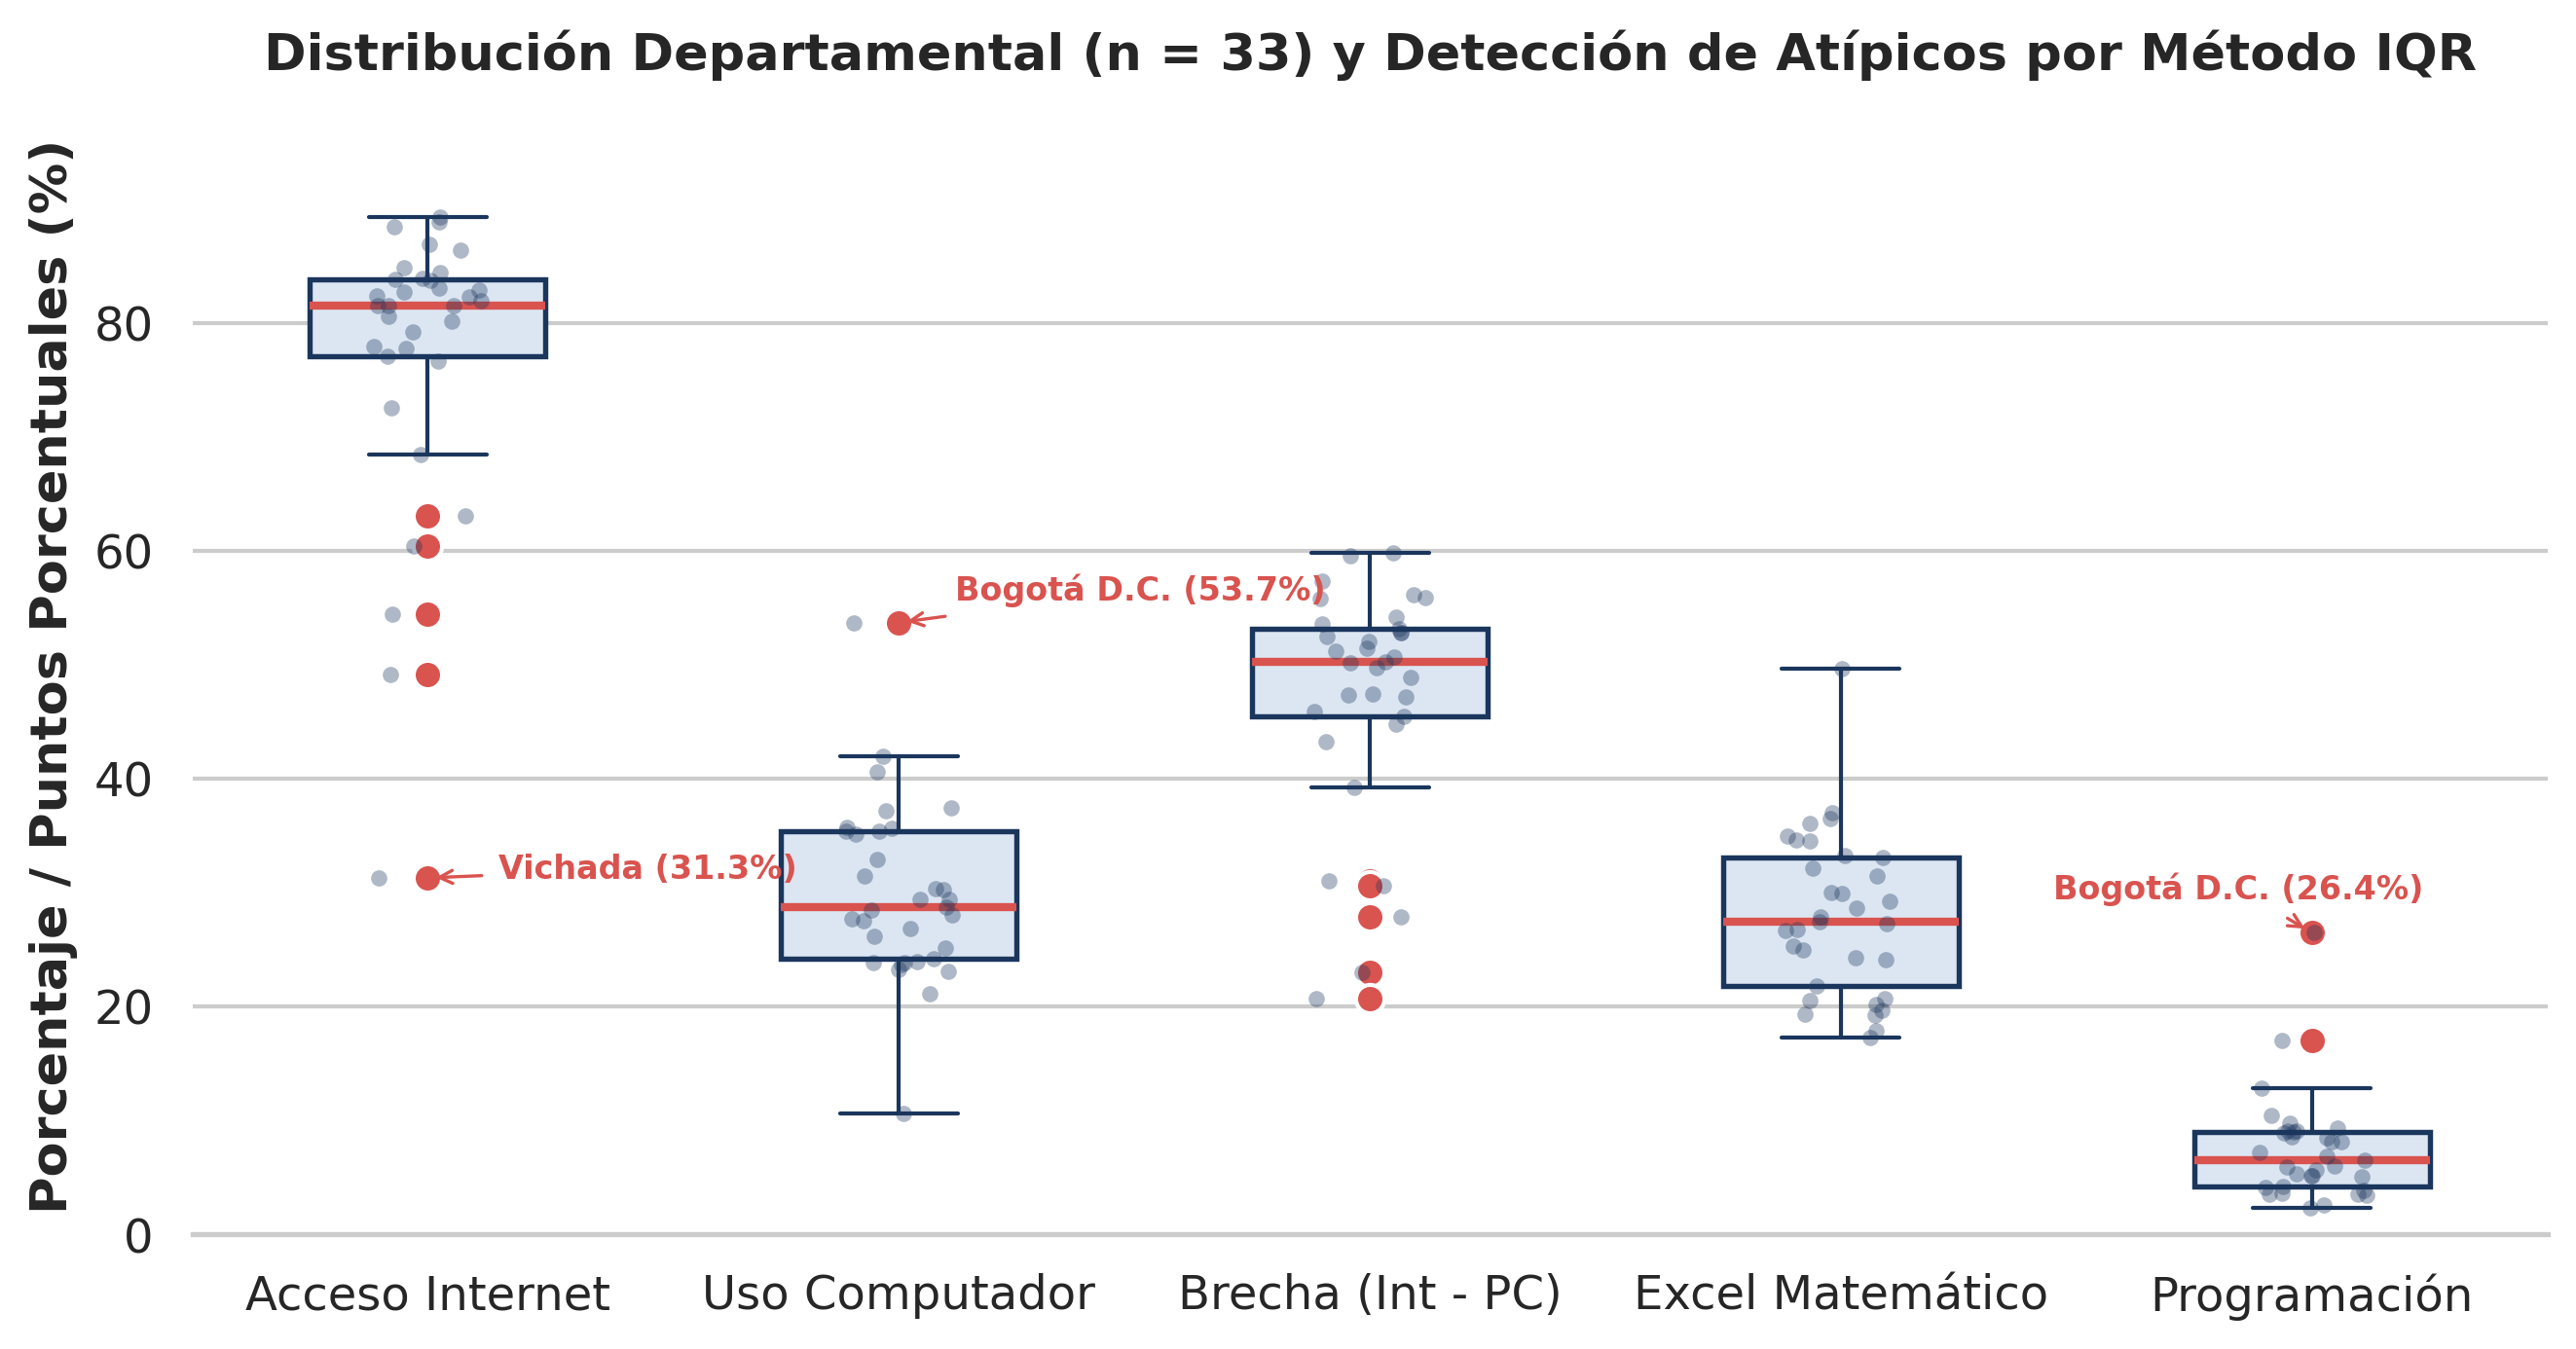

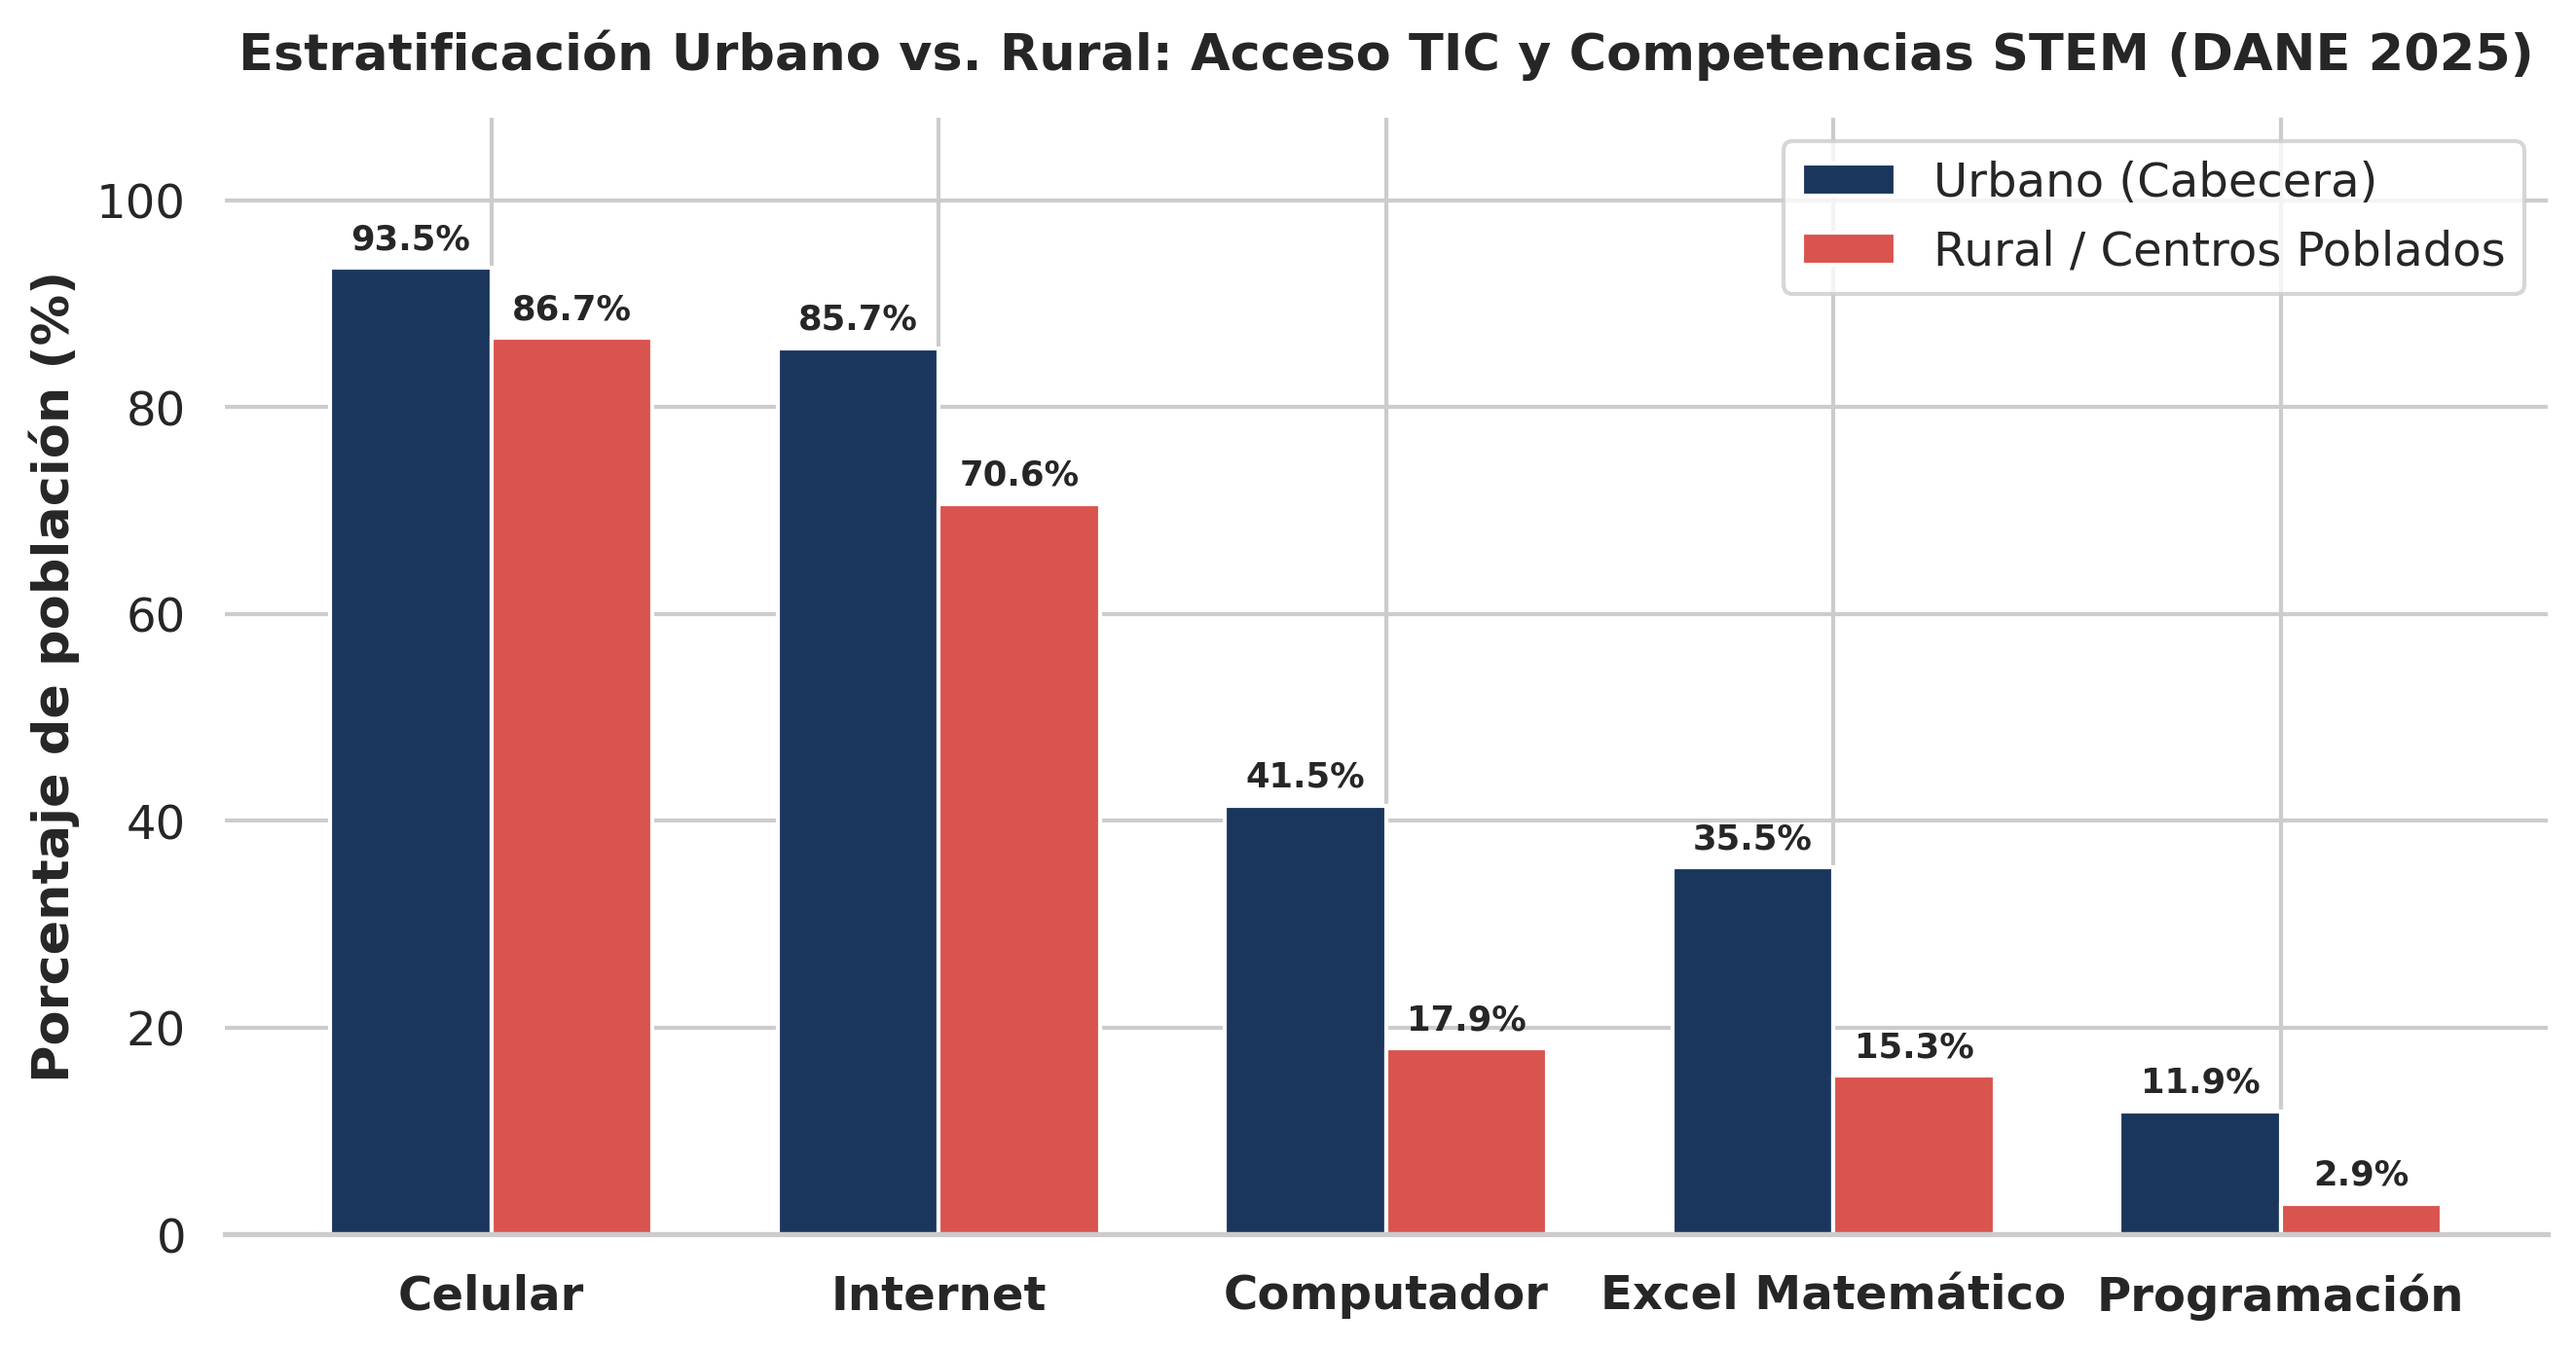

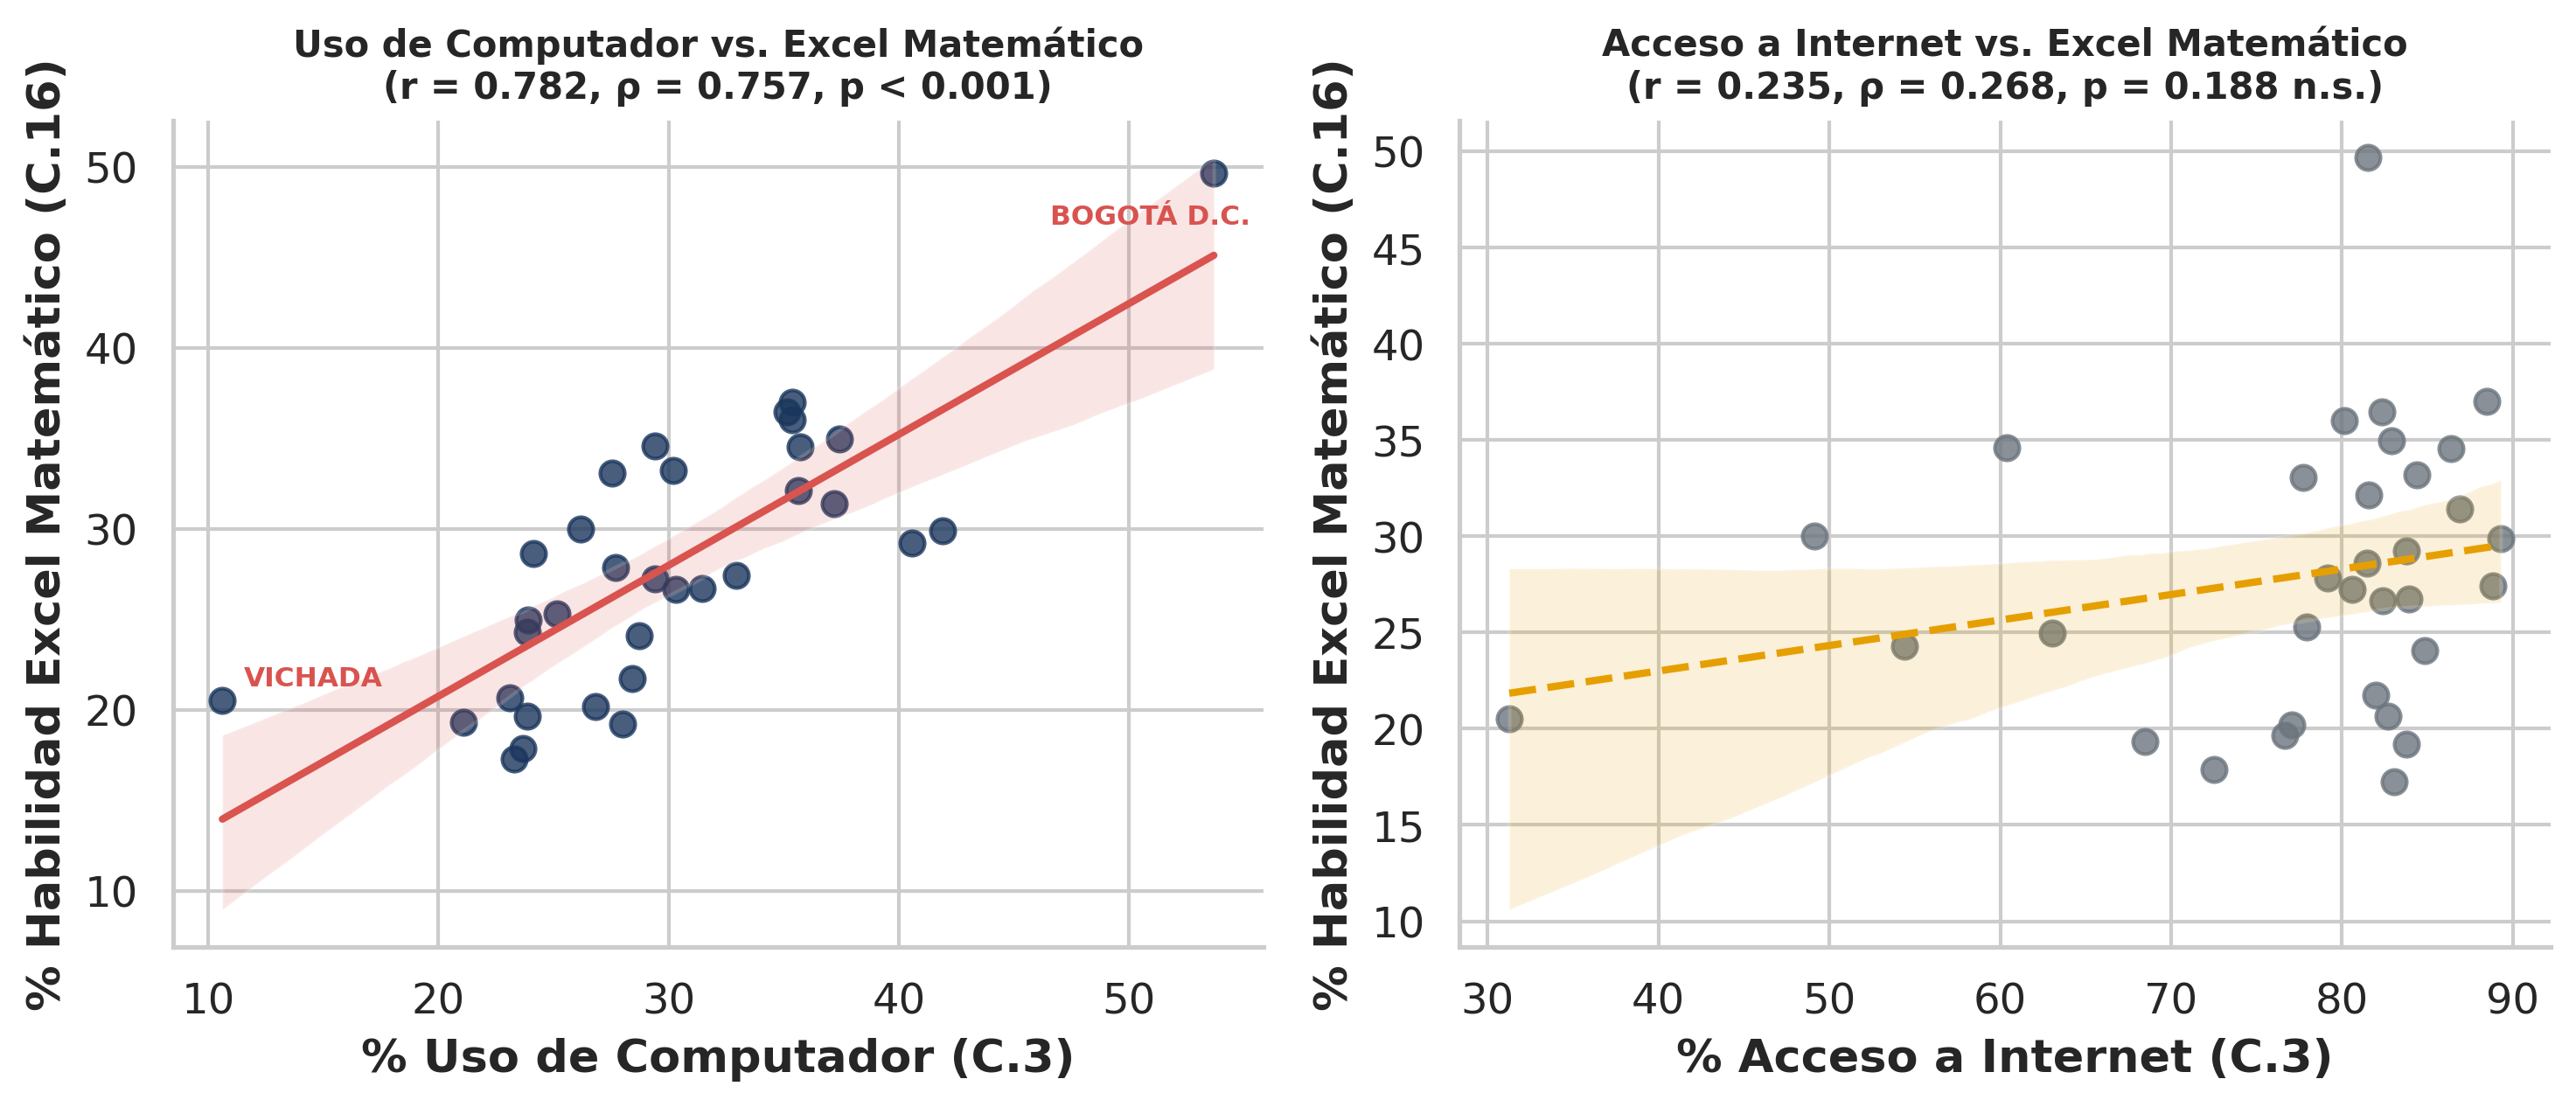


Gráficas exportadas a 300 dpi: fig1_atipicos_iqr.png, fig2_estratificacion_area.png, fig3_correlacion_stem.png


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Semilla fija para reproducibilidad
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ==============================================================================
# 1. CARGA DEL MODELO ESTRELLA GENERADO EN LA CELDA ANTERIOR
# ==============================================================================
xlsx_path = 'Modelo_Estrella_PowerBI_TICH2025.xlsx'

dim_depto = pd.read_excel(xlsx_path, sheet_name='Dim_Departamento')
dim_area  = pd.read_excel(xlsx_path, sheet_name='Dim_Area')
dim_sexo  = pd.read_excel(xlsx_path, sheet_name='Dim_Sexo')
dim_nivel = pd.read_excel(xlsx_path, sheet_name='Dim_Nivel_Educativo')

fact_c3  = pd.read_excel(xlsx_path, sheet_name='Fact_C3_Acceso_TIC')
fact_c5  = pd.read_excel(xlsx_path, sheet_name='Fact_C5_Dispositivos')
fact_c15 = pd.read_excel(xlsx_path, sheet_name='Fact_C15_Nivel_Educativo')
fact_c16 = pd.read_excel(xlsx_path, sheet_name='Fact_C16_Habilidades')

print("=== AUDITORÍA DE VALORES FALTANTES (POST-ETL) ===")
for nombre, df in [('Fact_C3', fact_c3), ('Fact_C5', fact_c5), ('Fact_C15', fact_c15), ('Fact_C16', fact_c16)]:
    print(f"  {nombre}: {df.shape[0]} filas x {df.shape[1]} columnas | Nulos: {df.isna().sum().sum()}")

# ==============================================================================
# 2. ESTRATIFICACIÓN POR SUBGRUPOS (ÁREA, SEXO Y COHORTE SECUNDARIA)
# ==============================================================================
# 2.1 Por Área (Urbano vs. Rural)
c3_area = fact_c3.merge(dim_area, on='Area_ID').groupby('Area_Corta').agg(
    Pob=('Total_Personas_5_Mas', 'sum'),
    PC=('Uso_Computador_Total', 'sum'),
    Internet=('Uso_Internet', 'sum'),
    Celular=('Uso_Celular', 'sum'),
    Base_C16=('Base_PC_Internet_C16', 'sum')
)
c16_area = fact_c16.merge(dim_area, on='Area_ID').groupby(['Area_Corta', 'Habilidad'])['Usuarios_Miles'].sum().unstack()

c3_area['Pct_Internet'] = c3_area['Internet'] / c3_area['Pob'] * 100
c3_area['Pct_PC']       = c3_area['PC'] / c3_area['Pob'] * 100
c3_area['Pct_Celular']  = c3_area['Celular'] / c3_area['Pob'] * 100
c3_area['Brecha_pp']    = c3_area['Pct_Internet'] - c3_area['Pct_PC']
c3_area['Pct_Excel']    = c16_area['Fórmulas matemáticas en hoja de cálculo'] / c3_area['Base_C16'] * 100
c3_area['Pct_Prog']     = c16_area['Lenguaje de programación especializado'] / c3_area['Base_C16'] * 100

print("\n=== TABLA 4A: ESTRATIFICACIÓN POR ÁREA ===")
print(c3_area[['Pob', 'Pct_Internet', 'Pct_PC', 'Pct_Celular', 'Brecha_pp', 'Pct_Excel', 'Pct_Prog']].round(2))

# 2.2 Por Sexo
c3_sexo = fact_c3.merge(dim_sexo, on='Sexo_ID').groupby('Sexo_Etiqueta').agg(
    Pob=('Total_Personas_5_Mas', 'sum'),
    PC=('Uso_Computador_Total', 'sum'),
    Internet=('Uso_Internet', 'sum'),
    Base_C16=('Base_PC_Internet_C16', 'sum')
)
c16_sexo = fact_c16.merge(dim_sexo, on='Sexo_ID').groupby(['Sexo_Etiqueta', 'Habilidad'])['Usuarios_Miles'].sum().unstack()

c3_sexo['Pct_Internet'] = c3_sexo['Internet'] / c3_sexo['Pob'] * 100
c3_sexo['Pct_PC']       = c3_sexo['PC'] / c3_sexo['Pob'] * 100
c3_sexo['Brecha_pp']    = c3_sexo['Pct_Internet'] - c3_sexo['Pct_PC']
c3_sexo['Pct_Excel']    = c16_sexo['Fórmulas matemáticas en hoja de cálculo'] / c3_sexo['Base_C16'] * 100
c3_sexo['Pct_Prog']     = c16_sexo['Lenguaje de programación especializado'] / c3_sexo['Base_C16'] * 100

print("\n=== TABLA 4B: ESTRATIFICACIÓN POR SEXO ===")
print(c3_sexo[['Pob', 'Pct_Internet', 'Pct_PC', 'Brecha_pp', 'Pct_Excel', 'Pct_Prog']].round(2))

# 2.3 Cohorte Secundaria (C.15) por Área
c15_merged = fact_c15.merge(dim_area, on='Area_ID').merge(dim_nivel, on='Nivel_ID')
c15_sec = c15_merged[c15_merged['Grupo_Proyecto'] == 'Población Objetivo (Secundaria)'].groupby('Area_Corta').agg(
    Pob=('Total_Personas_5_Mas', 'sum'),
    PC=('Uso_Computador', 'sum'),
    Internet=('Uso_Internet', 'sum')
)
c15_sec['Pct_Internet'] = c15_sec['Internet'] / c15_sec['Pob'] * 100
c15_sec['Pct_PC']       = c15_sec['PC'] / c15_sec['Pob'] * 100
c15_sec['Brecha_pp']    = c15_sec['Pct_Internet'] - c15_sec['Pct_PC']

print("\n=== TABLA 4C: COHORTE SECUNDARIA (C.15) POR ÁREA ===")
print(c15_sec[['Pob', 'Pct_Internet', 'Pct_PC', 'Brecha_pp']].round(2))

# ==============================================================================
# 3. PRUEBAS CHI-CUADRADO Y TAMAÑO DEL EFECTO (V DE CRAMÉR)
# ==============================================================================
def chi2_cramers_v(tabla_contingencia):
    chi2, p, dof, _ = stats.chi2_contingency(tabla_contingencia)
    n = tabla_contingencia.sum()
    min_dim = min(tabla_contingencia.shape) - 1
    v = np.sqrt(chi2 / (n * min_dim))
    return chi2, p, v

print("\n=== TABLA 5A: PRUEBAS CHI-CUADRADO Y V DE CRAMÉR ===")
# A: Área x Uso PC
cont_area_pc = np.array([
    [c3_area.loc['Urbano (Cabecera)', 'PC'], c3_area.loc['Urbano (Cabecera)', 'Pob'] - c3_area.loc['Urbano (Cabecera)', 'PC']],
    [c3_area.loc['Rural / Centros Poblados', 'PC'], c3_area.loc['Rural / Centros Poblados', 'Pob'] - c3_area.loc['Rural / Centros Poblados', 'PC']]
])
chi2_a, p_a, v_a = chi2_cramers_v(cont_area_pc)
print(f"  Área x Uso PC:               chi2 = {chi2_a:,.2f} | p = {p_a:.2e} | V de Cramér = {v_a:.4f}")

# B: Área x Excel Matemático
u_ex = c16_area.loc['Urbano (Cabecera)', 'Fórmulas matemáticas en hoja de cálculo']
r_ex = c16_area.loc['Rural / Centros Poblados', 'Fórmulas matemáticas en hoja de cálculo']
cont_area_ex = np.array([
    [u_ex, c3_area.loc['Urbano (Cabecera)', 'Base_C16'] - u_ex],
    [r_ex, c3_area.loc['Rural / Centros Poblados', 'Base_C16'] - r_ex]
])
chi2_b, p_b, v_b = chi2_cramers_v(cont_area_ex)
print(f"  Área x Excel Matemático:     chi2 = {chi2_b:,.2f} | p = {p_b:.2e} | V de Cramér = {v_b:.4f}")

# C: Área x Programación
u_pr = c16_area.loc['Urbano (Cabecera)', 'Lenguaje de programación especializado']
r_pr = c16_area.loc['Rural / Centros Poblados', 'Lenguaje de programación especializado']
cont_area_pr = np.array([
    [u_pr, c3_area.loc['Urbano (Cabecera)', 'Base_C16'] - u_pr],
    [r_pr, c3_area.loc['Rural / Centros Poblados', 'Base_C16'] - r_pr]
])
chi2_c, p_c, v_c = chi2_cramers_v(cont_area_pr)
print(f"  Área x Programación:         chi2 = {chi2_c:,.2f} | p = {p_c:.2e} | V de Cramér = {v_c:.4f}")

# D: Secundaria vs Superior x Uso PC (C.15)
c15_grp = c15_merged.groupby('Grupo_Proyecto').agg(Pob=('Total_Personas_5_Mas', 'sum'), PC=('Uso_Computador', 'sum'))
cont_edu_pc = np.array([
    [c15_grp.loc['Población Objetivo (Secundaria)', 'PC'], c15_grp.loc['Población Objetivo (Secundaria)', 'Pob'] - c15_grp.loc['Población Objetivo (Secundaria)', 'PC']],
    [c15_grp.loc['Educación Superior', 'PC'], c15_grp.loc['Educación Superior', 'Pob'] - c15_grp.loc['Educación Superior', 'PC']]
])
chi2_d, p_d, v_d = chi2_cramers_v(cont_edu_pc)
print(f"  Secundaria vs Sup. x Uso PC: chi2 = {chi2_d:,.2f} | p = {p_d:.2e} | V de Cramér = {v_d:.4f}")

# ==============================================================================
# 4. ESTADÍSTICOS DEPARTAMENTALES, ATÍPICOS (IQR) Y CORRELACIONES (n = 33)
# ==============================================================================
dep_c3 = fact_c3.merge(dim_depto, on='Departamento_ID').groupby('Departamento').agg(
    Pob=('Total_Personas_5_Mas', 'sum'),
    PC=('Uso_Computador_Total', 'sum'),
    Internet=('Uso_Internet', 'sum'),
    Base_C16=('Base_PC_Internet_C16', 'sum')
)
dep_c16 = fact_c16.merge(dim_depto, on='Departamento_ID').groupby(['Departamento', 'Habilidad'])['Usuarios_Miles'].sum().unstack()

dep_c3['Acceso Internet']   = dep_c3['Internet'] / dep_c3['Pob'] * 100
dep_c3['Uso Computador']    = dep_c3['PC'] / dep_c3['Pob'] * 100
dep_c3['Brecha (Int - PC)'] = dep_c3['Acceso Internet'] - dep_c3['Uso Computador']
dep_c3['Excel Matemático']  = dep_c16['Fórmulas matemáticas en hoja de cálculo'] / dep_c3['Base_C16'] * 100
dep_c3['Programación']      = dep_c16['Lenguaje de programación especializado'] / dep_c3['Base_C16'] * 100

cols_ind = ['Acceso Internet', 'Uso Computador', 'Brecha (Int - PC)', 'Excel Matemático', 'Programación']
desc = dep_c3[cols_ind].describe().T
desc['IQR'] = desc['75%'] - desc['25%']

print("\n=== TABLA 3: ESTADÍSTICOS DEPARTAMENTALES (n = 33) ===")
print(desc[['mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR']].round(2))

print("\n=== DETECCIÓN DE ATÍPICOS (REGLA 1.5 x IQR) ===")
for col in cols_ind:
    q1, q3 = dep_c3[col].quantile(0.25), dep_c3[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = dep_c3[(dep_c3[col] < lim_inf) | (dep_c3[col] > lim_sup)][col]
    print(f"  {col} [{lim_inf:.1f}, {lim_sup:.1f}]: {dict(atipicos.round(2))}")

print("\n=== TABLA 5B: CORRELACIONES DEPARTAMENTALES (n = 33) ===")
pares = [
    ('Uso Computador', 'Excel Matemático'),
    ('Uso Computador', 'Programación'),
    ('Acceso Internet', 'Excel Matemático'),
    ('Acceso Internet', 'Programación')
]
for x_col, y_col in pares:
    r, pr = stats.pearsonr(dep_c3[x_col], dep_c3[y_col])
    rho, prho = stats.spearmanr(dep_c3[x_col], dep_c3[y_col])
    print(f"  {x_col} vs {y_col}: Pearson r = {r:.3f} (p = {pr:.3e}) | Spearman rho = {rho:.3f} (p = {prho:.3e})")

# ==============================================================================
# 5. GENERACIÓN DE GRÁFICAS DE ALTA RESOLUCIÓN (300 DPI)
# ==============================================================================
sns.set_theme(style="whitegrid", font_scale=1.05)
NAVY, CORAL, AMBER, SLATE = "#1B365D", "#D9534F", "#E69F00", "#6C757D"

# --- FIGURA 1: Boxplots y Atípicos IQR ---
df_melt = dep_c3[cols_ind].reset_index().melt(id_vars='Departamento', var_name='Indicador', value_name='Porcentaje')
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=300)
sns.boxplot(data=df_melt, x='Indicador', y='Porcentaje', ax=ax, width=0.5,
            boxprops=dict(facecolor='#DCE6F2', edgecolor=NAVY, linewidth=1.3),
            medianprops=dict(color=CORAL, linewidth=2),
            whiskerprops=dict(color=NAVY), capprops=dict(color=NAVY),
            flierprops=dict(marker='o', markerfacecolor=CORAL, markeredgecolor='white', markersize=7))
sns.stripplot(data=df_melt, x='Indicador', y='Porcentaje', ax=ax, color=NAVY, alpha=0.35, size=4, jitter=0.12)

for xi, yi, txt, (dx, dy) in [
    (0, dep_c3.loc['VICHADA', 'Acceso Internet'], 'Vichada (31.3%)', (0.15, 0)),
    (1, dep_c3.loc['BOGOTÁ D.C.', 'Uso Computador'], 'Bogotá D.C. (53.7%)', (0.12, 2)),
    (4, dep_c3.loc['BOGOTÁ D.C.', 'Programación'], 'Bogotá D.C. (26.4%)', (-0.55, 3)),
]:
    ax.annotate(txt, xy=(xi, yi), xytext=(xi + dx, yi + dy),
                fontsize=8, fontweight='bold', color=CORAL,
                arrowprops=dict(arrowstyle='->', color=CORAL, lw=0.8))

ax.set_title('Distribución Departamental (n = 33) y Detección de Atípicos por Método IQR', fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('Porcentaje / Puntos Porcentuales (%)', fontweight='bold')
ax.set_ylim(0, 98)
sns.despine(left=True)
plt.tight_layout()
plt.savefig('fig1_atipicos_iqr.png', dpi=300)
plt.show()

# --- FIGURA 2: Estratificación Urbano vs. Rural ---
metricas = ['Celular', 'Internet', 'Computador', 'Excel Matemático', 'Programación']
cols_m   = ['Pct_Celular', 'Pct_Internet', 'Pct_PC', 'Pct_Excel', 'Pct_Prog']
urb = [c3_area.loc['Urbano (Cabecera)', c] for c in cols_m]
rur = [c3_area.loc['Rural / Centros Poblados', c] for c in cols_m]

x = np.arange(len(metricas))
w = 0.36
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=300)
b1 = ax.bar(x - w/2, urb, w, label='Urbano (Cabecera)', color=NAVY)
b2 = ax.bar(x + w/2, rur, w, label='Rural / Centros Poblados', color=CORAL)

for bars in [b1, b2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax.set_ylabel('Porcentaje de población (%)', fontweight='bold')
ax.set_title('Estratificación Urbano vs. Rural: Acceso TIC y Competencias STEM (DANE 2025)', fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metricas, fontweight='bold')
ax.set_ylim(0, 108)
ax.legend(frameon=True, loc='upper right')
sns.despine(left=True)
plt.tight_layout()
plt.savefig('fig2_estratificacion_area.png', dpi=300)
plt.show()

# --- FIGURA 3: Contraste Correlacional (Ilusión de Digitalización) ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), dpi=300)

r1, _ = stats.pearsonr(dep_c3['Uso Computador'], dep_c3['Excel Matemático'])
rho1, _ = stats.spearmanr(dep_c3['Uso Computador'], dep_c3['Excel Matemático'])
sns.regplot(data=dep_c3, x='Uso Computador', y='Excel Matemático', ax=axes[0],
            scatter_kws={'color': NAVY, 's': 45, 'alpha': 0.8}, line_kws={'color': CORAL, 'lw': 2})
axes[0].set_title(f'Uso de Computador vs. Excel Matemático\n(r = {r1:.3f}, ρ = {rho1:.3f}, p < 0.001)', fontweight='bold', fontsize=10)
axes[0].set_xlabel('% Uso de Computador (C.3)', fontweight='bold')
axes[0].set_ylabel('% Habilidad Excel Matemático (C.16)', fontweight='bold')

for dep_lbl, offset in [('BOGOTÁ D.C.', (-45, -14)), ('VICHADA', (6, 4))]:
    axes[0].annotate(dep_lbl, (dep_c3.loc[dep_lbl, 'Uso Computador'], dep_c3.loc[dep_lbl, 'Excel Matemático']),
                     xytext=offset, textcoords='offset points', fontsize=7.5, fontweight='bold', color=CORAL)

r2, p2 = stats.pearsonr(dep_c3['Acceso Internet'], dep_c3['Excel Matemático'])
rho2, _ = stats.spearmanr(dep_c3['Acceso Internet'], dep_c3['Excel Matemático'])
sns.regplot(data=dep_c3, x='Acceso Internet', y='Excel Matemático', ax=axes[1],
            scatter_kws={'color': SLATE, 's': 45, 'alpha': 0.8}, line_kws={'color': AMBER, 'lw': 2, 'ls': '--'})
axes[1].set_title(f'Acceso a Internet vs. Excel Matemático\n(r = {r2:.3f}, ρ = {rho2:.3f}, p = {p2:.3f} n.s.)', fontweight='bold', fontsize=10)
axes[1].set_xlabel('% Acceso a Internet (C.3)', fontweight='bold')
axes[1].set_ylabel('% Habilidad Excel Matemático (C.16)', fontweight='bold')

sns.despine()
plt.tight_layout()
plt.savefig('fig3_correlacion_stem.png', dpi=300)
plt.show()

print("\nGráficas exportadas a 300 dpi: fig1_atipicos_iqr.png, fig2_estratificacion_area.png, fig3_correlacion_stem.png")